# Task 2.1: bit flip rate $\Gamma_X$

**Answer.** At the challenge cat size $\alpha=2.1$, $\Gamma_X=3.85\times10^{-7}\ \mu\mathrm{s}^{-1}$: an amplitude-relaxation time $1/\Gamma_X=2.6$ s. We get it two ways. Brute force time evolution works up to $\alpha=1.4$. The Liouvillian eigenvalue covers larger cats. Where both run, they agree to $10^{-8}$.

**Definition.** Start in $\lvert\alpha\rangle_a\lvert0\rangle_b$ with $\epsilon_d=g_2\alpha^2$. Evolve the full two-mode master equation, with jumps $\sqrt{\kappa_a}a$ and $\sqrt{\kappa_b}b$ and no elimination. Then fit

$$\mathrm{Re}\langle a\rangle(t)=A e^{-\Gamma_X t},\qquad t\ge2\ \mu\mathrm{s}.$$

For symmetric flips at rate $r$ in each direction, $\Gamma_X=2r$. Saved results load by default; set `RERUN=True` to recompute.

In [1]:
from pathlib import Path
import sys, json, io
from contextlib import redirect_stdout
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F
RERUN = False

## 1. Brute force: time evolution

α,Γ_X (1/µs),1/Γ_X (ms),change at larger cutoff
0.7,9.544e-03,0.1,2e-11
0.85,5.120e-03,0.2,2e-09
1,2.301e-03,0.43,6e-08
1.15,8.636e-04,1.2,1e-06
1.3,2.756e-04,3.6,1e-05
1.4,1.202e-04,8.3,4e-05


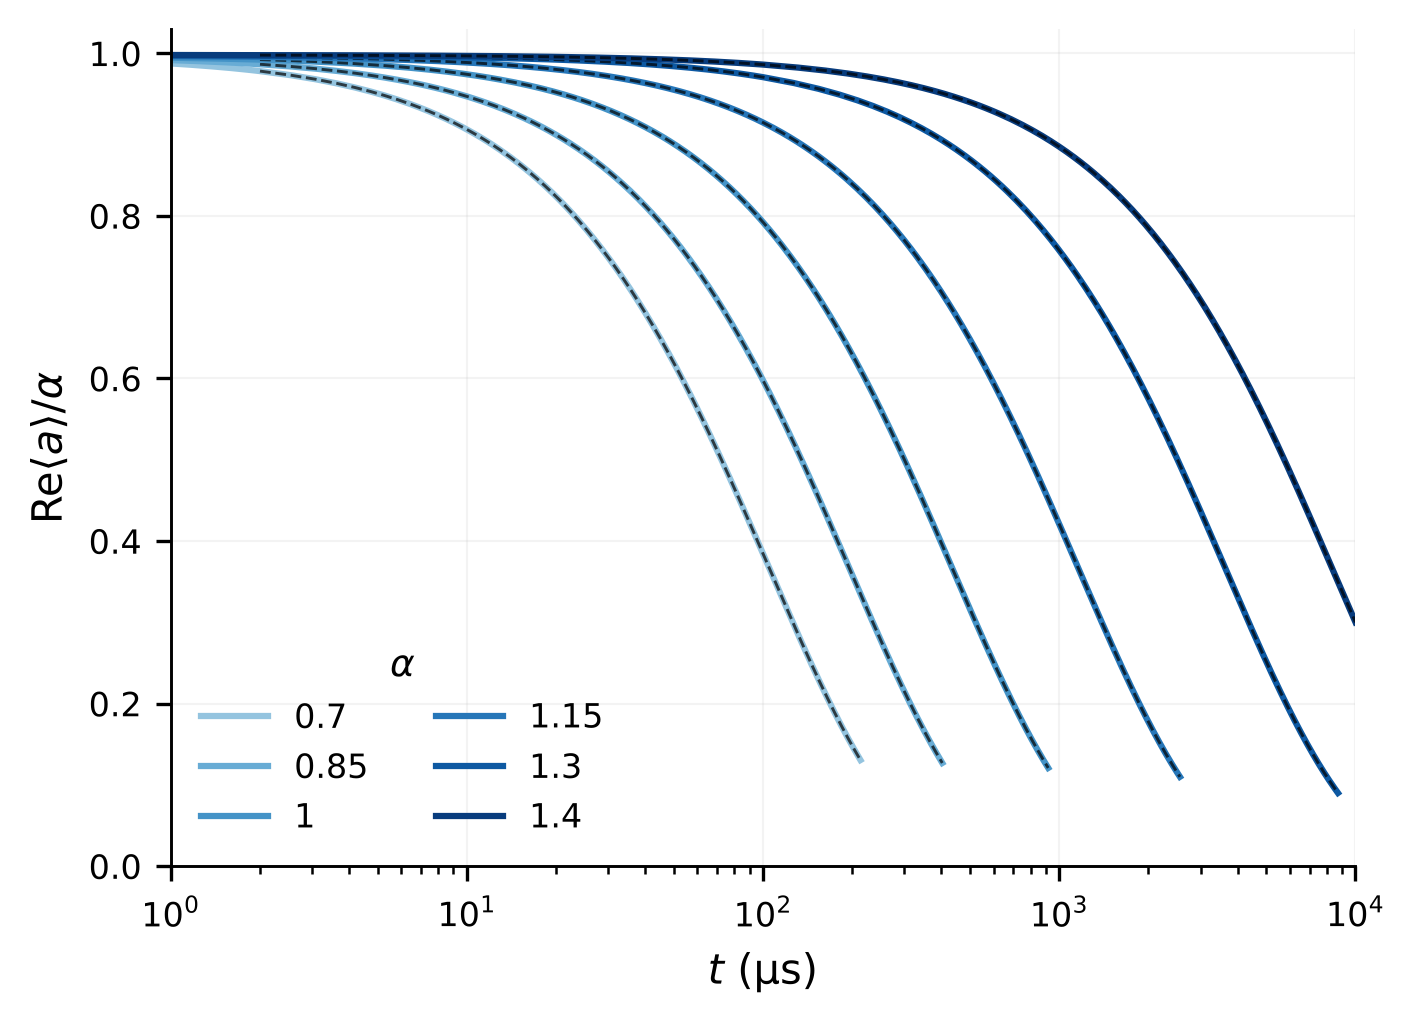

In [2]:
if RERUN:
    from tasks.task_2_1 import main
    main()
result = json.loads((ROOT / "results/task_2_1.json").read_text())
assert result["complete"]
display(pd.DataFrame([{
    "α": r["alpha"], "Γ_X (1/µs)": f"{r['fit']['gamma_per_us']:.3e}",
    "1/Γ_X (ms)": f"{r['fit']['tau_us'] / 1e3:.2g}",
    "change at larger cutoff": f"{r['checks']['cutoff_relative_change']:.0e}",
} for r in result["cases"]]).style.hide(axis="index").format({"α": "{:g}"}))
display(Image(filename=str(ROOT / "figures/task_2_1_bit_flips.png"), width=520))

**Time domain decay.** $\mathrm{Re}\langle a\rangle/\alpha$ from $\lvert\alpha\rangle_a\lvert0\rangle_b$ at truncation $(N_a,N_b)=(20,6)$. Colored lines are trajectories; black dashes are exponential fits from 2 µs. Each step in $\alpha$ stretches the lifetime about 2 to 3 times.

**Scaling.** A fit of $\Gamma_X=C e^{-\gamma\alpha^2}$ over $0.7\le\alpha\le1.4$ gives $\gamma=2.99$ ($R^2=0.9995$).

Projecting weak memory loss onto the orthonormal even/odd cat basis gives a first-order contribution $\Gamma_X^{(1)}=\kappa_a\alpha^2(\coth2\alpha^2-1)\approx2\kappa_a\alpha^2e^{-4\alpha^2}$. The asymptotic expression has local slope $-d\ln\Gamma_X^{(1)}/d\alpha^2=4-1/\alpha^2$, consistent with an effective exponent near 3 over this range.

At $\alpha=1.4$ the simulation is already 33% above this estimate. The larger-cat study below tests a second-order contribution.

**Checks.** At each $\alpha$, the fit is compared with the odd-block eigenvalue at the same truncation, an independent dynamiqs integration and other fit windows. The last column is the largest population on the top memory and buffer levels.

In [3]:
display(pd.DataFrame([{
    "α": r["alpha"],
    "fit vs eigenvalue": f"{r['checks']['fit_vs_eigen_relative_change']:.0e}",
    "fit vs dynamiqs": f"{r['checks']['dynamiqs_rate_relative_change']:.0e}",
    "fit window spread": f"{r['checks']['window_relative_spread']:.0e}",
    "top level population": f"{max(r['diagnostics']['max_top2_a'], r['diagnostics']['max_top1_b']):.0e}",
} for r in result["cases"]]).style.hide(axis="index").format({"α": "{:g}"}))

α,fit vs eigenvalue,fit vs dynamiqs,fit window spread,top level population
0.7,6e-09,1e-08,6e-09,1e-13
0.85,3e-09,1e-08,3e-09,4e-12
1,8e-10,1e-08,7e-10,6e-11
1.15,7e-10,4e-08,8e-10,4e-10
1.3,3e-10,6e-08,4e-10,2e-09
1.4,4e-10,2e-07,5e-10,5e-09


## 2. Beyond brute force: the eigenvalue

At $\alpha=2.1$ amplitude relaxation takes 2.6 s, about $4\times10^{7}$ times the buffer time $1/\kappa_b\approx60$ ns. Resolving that in the time domain is impractical.

The Liouvillian $\mathcal L$ governs density-matrix evolution; an eigenmode with eigenvalue $\lambda$ decays at rate $-\mathrm{Re}\lambda$. Memory parity symmetry, $a\to-a$, splits $\mathcal L$ into even and odd blocks. The amplitude $\mathrm{Re}\langle a\rangle$ is odd, so its slow decay is associated with an odd mode. A sparse shift-invert solve (`src/spectral.py`) extracts eigenvalues near zero. We identify the relevant mode by agreement with the time domain fits where those are feasible; this is not a search over the entire spectrum.

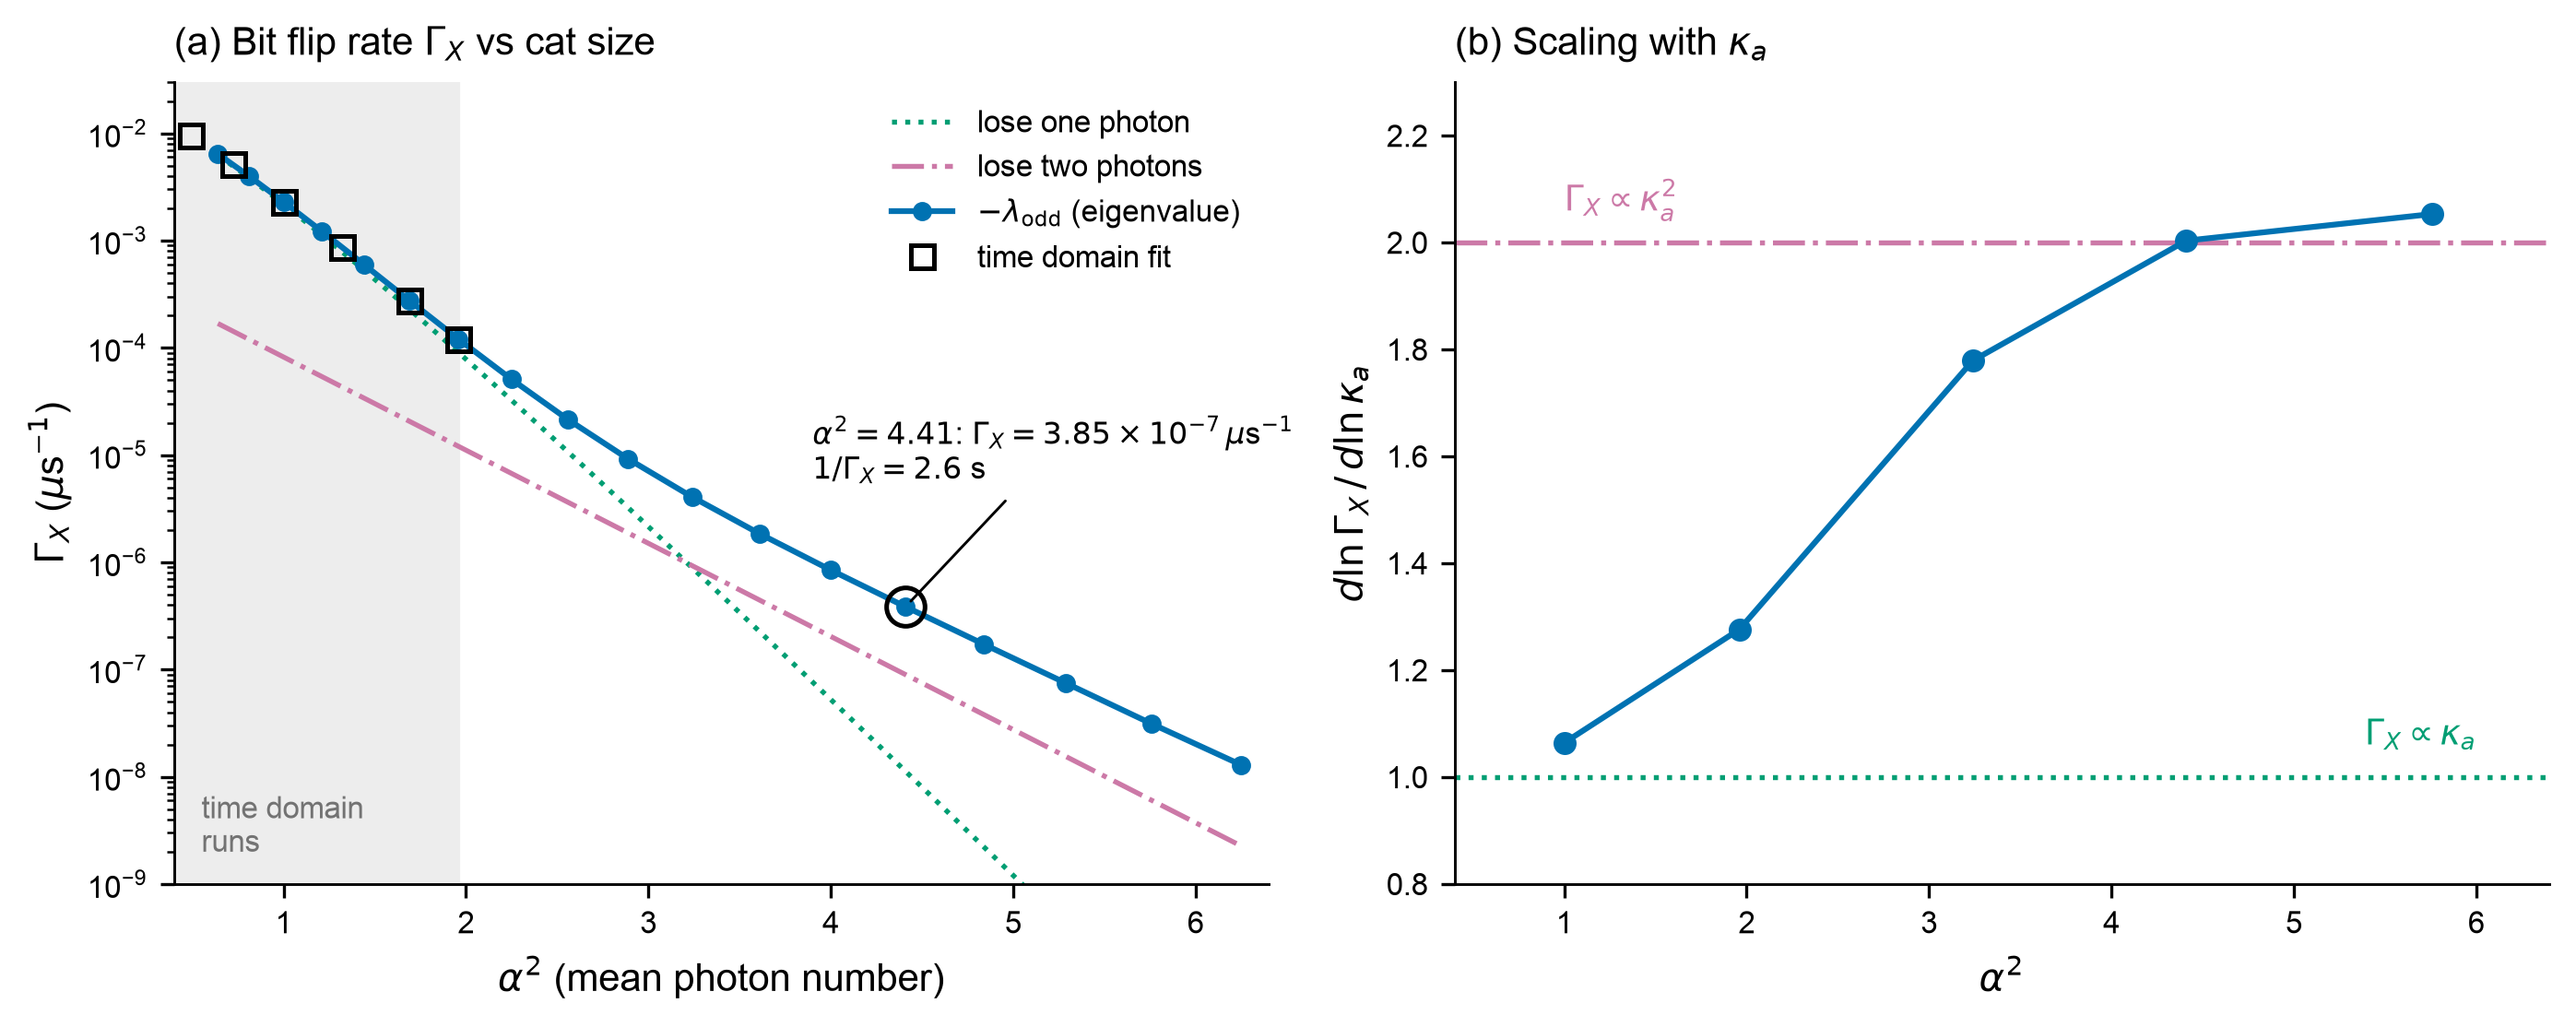

In [4]:
with redirect_stdout(io.StringIO()):
    F.bit_flips()
display(Image(filename=str(ROOT / "figures/s2/task_2_1_large_cats.png"), width=1000))

**First- and second-order loss contributions.** (a) Squares are the time domain fits. Blue is $-\mathrm{Re}\lambda_{\rm odd}$ at the largest tested truncation, up to $\alpha=2.5$. The cutoff comparison is tabulated below.
- *Lose one photon* (green): the first-order, ideal cat-space estimate, $\kappa_a\alpha^2(\coth2\alpha^2-1)\approx2\kappa_a\alpha^2e^{-4\alpha^2}$.
- *Lose two photons* (pink): the second-order contribution from finite stabilization and excursions outside the ideal cat space, $(\kappa_a^2/\kappa_2)e^{-2\alpha^2}$ ([Dubovitskii 2025](https://arxiv.org/abs/2407.17299)).

These labels denote perturbative orders in $\kappa_a$, not individually observed jump sequences. Blue follows green for small cats and runs parallel to pink for large ones. Both lines are one-mode formulas, so they predict the slope, not the size. At $\alpha=2.1$ the one-mode model (buffer eliminated) gives $1.17\times10^{-7}\ \mu\mathrm{s}^{-1}$, close to their sum. The full model is 3.3 times faster because the buffer is slow (table below).

(b) The test of the handover: sweep $\kappa_a\times\lbrace \tfrac14,\tfrac12,1,2,4\rbrace$ and fit $\Gamma_X\propto\kappa_a^{s}$. A contribution linear in $\kappa_a$ gives $s=1$; a quadratic contribution gives $s=2$. $s$ reaches 2 at $\alpha=2.1$; the 2.05 at $\alpha=2.4$ is unexplained.

In [5]:
rows = [d for d in F.load("gx_two_*.json") if F.nominal(d)]
eig = {a: d for a, d in F.largest(rows).items() if a <= 2.5}
one = F.largest(d for d in F.load("gx_one_*.json") if F.nominal(d))
al = np.array(list(eig)); gx = np.array([d["gamma_x"] for d in eig.values()])
local_gamma = dict(zip(al, -np.gradient(np.log(gx), al**2)))

print("Same α, both methods. The eigenvalue at the same truncation agrees to 1e-8; the last column adds truncation error.")
display(pd.DataFrame([{
    "α": r["alpha"], "time domain fit, 20×6": f"{r['fit']['gamma_per_us']:.6e}",
    "eigenvalue, 20×6": f"{r['eigenvalue']['gamma_per_us']:.6e}",
    "eigenvalue, largest": f"{eig[round(r['alpha'], 2)]['gamma_x']:.6e}",
} for r in result["cases"] if round(r["alpha"], 2) in eig]).style.hide(axis="index").format({"α": "{:g}"}))

print("Large cats (eigenvalue only).")
display(pd.DataFrame([{
    "α": a, "Γ_X (1/µs)": f"{eig[a]['gamma_x']:.3e}", "1/Γ_X (s)": f"{1e-6 / eig[a]['gamma_x']:.2g} s",
    "local γ": f"{local_gamma[a]:.2f}", "full / one-mode": f"{eig[a]['gamma_x'] / one[a]['gamma_x']:.1f}",
    "truncation spread": f"{max(abs(d['gamma_x'] / eig[a]['gamma_x'] - 1) for d in rows if round(d['alpha'], 2) == a):.0e}",
} for a in (1.4, 1.8, 2.1, 2.4)]).style.hide(axis="index").format({"α": "{:g}"}))

Same α, both methods. The eigenvalue at the same truncation agrees to 1e-8; the last column adds truncation error.


α,"time domain fit, 20×6","eigenvalue, 20×6","eigenvalue, largest"
1,2.300656e-03,2.300656e-03,2.300656e-03
1.3,2.756441e-04,2.756441e-04,2.756478e-04
1.4,1.202000e-04,1.202000e-04,1.202052e-04


Large cats (eigenvalue only).


α,Γ_X (1/µs),1/Γ_X (s),local γ,full / one-mode,truncation spread
1.4,1.202e-04,0.0083 s,3.02,1.1,8e-07
1.8,4.067e-06,0.25 s,2.23,2.0,6e-04
2.1,3.849e-07,2.6 s,1.90,3.3,9e-03
2.4,3.115e-08,32 s,1.83,4.5,1e-02


**Result.** $\Gamma_X(2.1)=3.85\times10^{-7}\ \mu\mathrm{s}^{-1}$, an amplitude-relaxation time of 2.6 s, with less than 1% variation across the tested cutoffs. For symmetric switching, the mean waiting time for a flip is $2/\Gamma_X=5.2$ s.

The exponent is not constant. The local $\gamma=-d\ln\Gamma_X/d\alpha^2$ peaks near 3.1 at $\alpha\approx1.2$ and falls to 1.9 by $\alpha=2.1$ as the two-loss route takes over, consistent with the prompt's $\gamma\lesssim2$. The slow buffer makes flips 3.3 times faster than the one-mode model at $\alpha=2.1$, and the gap grows with $\alpha$.

Limits: no thermal photons. The cutoff spread rises to about 1.5% at $\alpha=2.4$ and 2.2% at $\alpha=2.5$; larger cats are not reported as converged. Cutoff agreement and the small-cat time domain checks do not prove global spectral dominance at every cat size.